# 04 · Etiquetar miniaturas sin entrenar (zero-shot)

Si una miniatura y una palabra viven en el mismo espacio, podemos **etiquetar la imagen buscando las palabras más cercanas**, sin entrenar ningún clasificador. Eso es *zero-shot*.

Como vocabulario usamos las 3.806 etiquetas de YouTube-8M, embebidas como texto con EmbeddingGemma (`data/emb_vocab.parquet`). Y como cada video ya trae sus etiquetas reales, podemos medir **qué tan seguido acertamos**.

Es la misma idea que usa la web para describir los frames de un video en la línea de tiempo.

In [1]:
import sys
from pathlib import Path

# Los notebooks viven en notebooks/, pero los datos (data/) y el código (analysis/, recolect/)
# están en la raíz del repo. Así funcionan abriéndolos desde cualquiera de las dos carpetas.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))
# True para sobrescribir las figuras que usa el informe (informe/figs/)
GUARDAR_FIGS = False
FIGS = ROOT / "informe" / "figs"

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from analysis.metricas import REPRESENTACIONES, cargar_videos, cargar_vocabulario, matriz, zero_shot_topk, hit_at_k
from analysis.graficos import COLORES, INK, MUTED, GRID, estilo, thumb, corto

estilo()

In [3]:
df = cargar_videos()
vocab = cargar_vocabulario()

L = np.stack(vocab["emb"]).astype(np.float32)      # (3806, 768): un vector por etiqueta
nombres = vocab["Name"].to_numpy()                 # nombre de cada fila de L
ids = vocab["Index"].to_numpy()                    # id de etiqueta YT-8M de cada fila (el que aparece en df.labels)
print(f"{len(df):,} miniaturas · {len(vocab):,} etiquetas")

34,771 miniaturas · 3,806 etiquetas


## 1. Las etiquetas más cercanas a cada miniatura

Para cada miniatura calculamos la similitud con las 3.806 etiquetas y nos quedamos con las 10 más altas. Abajo, 8 ejemplos al azar con su top-5: el ✓ marca las etiquetas que el video tiene de verdad.

In [4]:
Xi = matriz(df, "image")
top = zero_shot_topk(Xi, L, k=10)        # posiciones en el vocabulario, de mayor a menor similitud
pred = ids[top]                          # -> ids de YT-8M, comparables con df.labels

findfont: Failed to find font weight bold for Arial Unicode MS, now using 400.


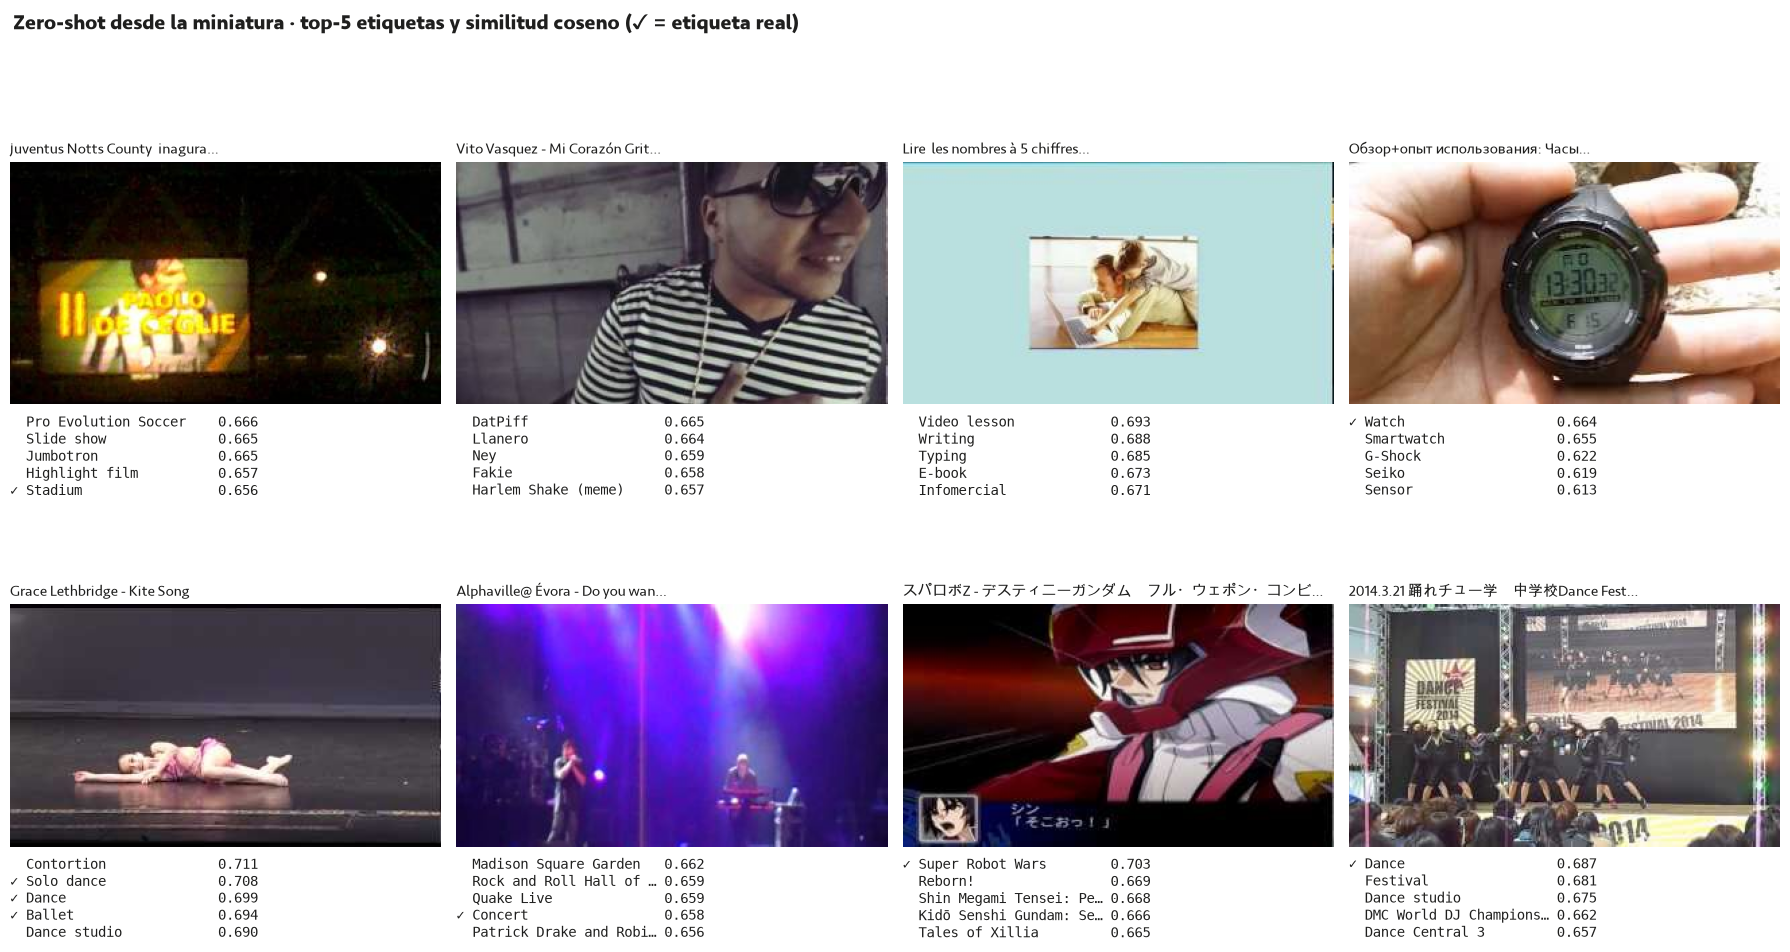

In [5]:
ej = df.sample(8, random_state=7).index

fig, axes = plt.subplots(2, 4, figsize=(18, 9.5))
for ax, i in zip(axes.flat, ej):
    ax.imshow(thumb(df.youtube_id[i]))
    ax.axis("off")
    reales = set(map(int, df.labels[i]))
    lineas = [f"{'✓' if ids[p] in reales else ' '} {corto(nombres[p], 22):<23} {L[p] @ Xi[i]:.3f}" for p in top[i, :5]]
    ax.set_title(corto(df.title[i], 30), fontsize=11, color=INK, loc="left")
    ax.text(0, -0.04, "\n".join(lineas), transform=ax.transAxes, va="top",
            fontsize=10, color=INK, family="DejaVu Sans Mono")
fig.suptitle("Zero-shot desde la miniatura · top-5 etiquetas y similitud coseno (✓ = etiqueta real)",
             x=0.01, ha="left", fontsize=15, fontweight="bold", color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.95), h_pad=8)
if GUARDAR_FIGS:
    fig.savefig(FIGS / "zeroshot_galeria.png", dpi=200, bbox_inches="tight")
plt.show()

Las similitudes quedan todas apretadas (la brecha de modalidad del notebook 03): entre el 1.º y el 5.º lugar hay diferencias de centésimas. Por eso lo que importa es el **orden**, no el valor. Aun cuando no hay ✓, las etiquetas suelen describir bien lo que se *ve*, aunque no sean las que YT-8M le asignó al video.

## 2. ¿Cuántas veces acertamos?

Usamos **hit@k**: la fracción de videos en que al menos una de las k etiquetas predichas es real. Lo calculamos para las cuatro representaciones de Gemma, y lo comparamos con un baseline tonto: predecir siempre las k etiquetas más frecuentes del dataset.

In [6]:
curvas = {}
for rep in ("image", "text", "imgtext", "fusion"):
    pred_rep = ids[zero_shot_topk(matriz(df, rep), L, k=10)]
    curvas[REPRESENTACIONES[rep]] = hit_at_k(pred_rep, df.labels)

mas_frecuentes = pd.Series(np.concatenate(df.labels.to_numpy())).value_counts().index[:10].to_numpy()
curvas["Baseline: las más frecuentes"] = hit_at_k(np.tile(mas_frecuentes, (len(df), 1)), df.labels)

hits = pd.DataFrame(curvas)
hits.loc[[1, 5, 10]].round(3)

,Gemma · imagen,Gemma · texto,Gemma · imagen + texto,Gemma · fusión tardía,Baseline: las más frecuentes
1,0.322,0.574,0.474,0.577,0.199
5,0.600,0.821,0.816,0.836,0.458
10,0.702,0.877,0.895,0.898,0.564


findfont: Failed to find font weight bold for Arial Unicode MS, now using 400.


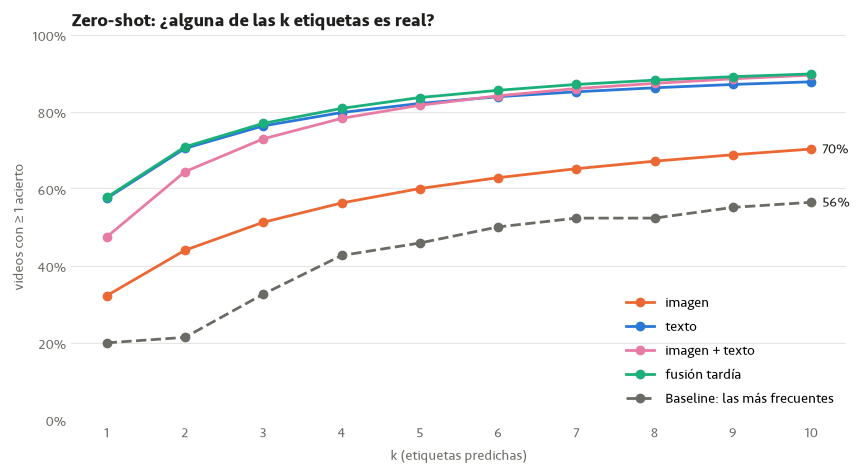

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
for nombre, serie in hits.items():
    base = nombre.startswith("Baseline")
    ax.plot(serie.index, serie.values, marker="o", ms=6, lw=2,
            color=MUTED if base else COLORES[nombre], ls="--" if base else "-",
            label=nombre.replace("Gemma · ", ""))
    if nombre in ("Gemma · imagen", "Baseline: las más frecuentes"):   # las otras tres quedan casi encima
        ax.annotate(f"{serie[10]:.0%}", (10, serie[10]), xytext=(8, 0), textcoords="offset points",
                    va="center", fontsize=10, color=INK)
ax.set_xticks(hits.index)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set_xlabel("k (etiquetas predichas)", color=MUTED)
ax.set_ylabel("videos con ≥ 1 acierto", color=MUTED)
ax.set_title("Zero-shot: ¿alguna de las k etiquetas es real?", loc="left", fontsize=13, fontweight="bold", color=INK)
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", color=GRID)
ax.tick_params(colors=MUTED, length=0)
for sp in ax.spines.values():
    sp.set_visible(False)
if GUARDAR_FIGS:
    fig.savefig(FIGS / "zeroshot_hitk.png", dpi=200, bbox_inches="tight")
plt.show()

El texto y las dos fusiones aciertan más: las etiquetas son palabras y muchas veces aparecen tal cual en el título o los tags. La curva de **imagen** es el zero-shot "honesto": solo mira píxeles, y aun así queda muy por encima del baseline.

## 3. ¿Qué categorías reconoce mejor la imagen?

No todos los temas se ven igual de bien en una miniatura. Un auto o un videojuego son fáciles de reconocer; una charla o un tutorial, no tanto.

findfont: Failed to find font weight bold for Arial Unicode MS, now using 400.


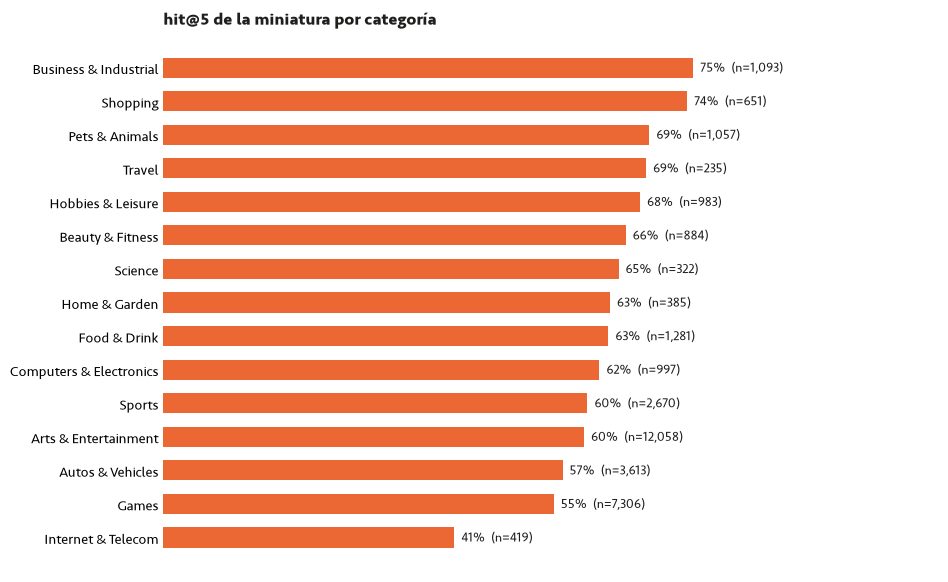

In [8]:
acierto5 = pd.Series([bool(set(p[:5]) & set(map(int, l))) for p, l in zip(pred, df.labels)])
por_cat = (acierto5.groupby(df.vertical).agg(["mean", "size"])
           .query("size >= 200").sort_values("mean"))     # solo categorías con suficientes videos

fig, ax = plt.subplots(figsize=(10, 0.4 * len(por_cat) + 1))
ax.barh(por_cat.index, por_cat["mean"], color="#eb6834", height=0.6)
for yy, (v, n) in enumerate(zip(por_cat["mean"], por_cat["size"])):
    ax.text(v + 0.01, yy, f"{v:.0%}  (n={n:,})", va="center", fontsize=9.5, color=INK)
ax.set_xlim(0, 1.1)
ax.xaxis.set_visible(False)
ax.set_title("hit@5 de la miniatura por categoría", loc="left", fontweight="bold", color=INK)
ax.tick_params(length=0)
for sp in ax.spines.values():
    sp.set_visible(False)
plt.show()

### en conclusión

- Sin entrenar nada, la miniatura sola ya acierta etiquetas reales en una buena fracción de los videos.
- El rendimiento depende mucho del tema: lo que tiene una apariencia reconocible se etiqueta bien.
- Es la base de dos funciones de la web: describir los frames de un video y ubicar en el mapa una foto cualquiera.